# 6. Protocolo y validación estadística

Este capítulo responde a la sección 6 de la guía: protocolo pre-registrado, equidad de la comparación, supuestos de cada prueba, al
menos tres pruebas de hipótesis, ajuste por comparaciones múltiples, intervalos de confianza y tamaños del efecto. Todo se refiere a
Home Credit con los 10 modelos en igualdad de condiciones. Los conjuntos adicionales y la robustez van en el capítulo 7.

Las pruebas se calcularon con `experiments/e10b_pruebas_igualdad.py` y `experiments/e15_estadistica_final.py` (funciones en
`experiments/comun.py`). Este cuaderno lee sus resultados y rehace los cálculos baratos (Holm global, diferencia crítica).

In [1]:
from pathlib import Path
import json
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import studentized_range

RAIZ = Path.cwd()                       # raiz del repositorio (sin rutas absolutas)
assert (RAIZ / "experiments" / "protocolo.md").is_file(), "Ejecute este cuaderno desde la raiz del repositorio"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
NOMBRE = {"elar": "ELAR-R", "xgboost": "XGBoost", "catboost": "CatBoost", "lightgbm": "LightGBM", "logistica": "Logistica",
          "svm": "SVM", "random_forest": "Random forest", "arbol": "Arbol", "knn": "KNN", "naive_bayes": "Naive Bayes"}
pe = json.loads((RAIZ / "resultados_e4" / "e10_igualdad" / "pruebas_elar.json").read_text(encoding="utf-8"))
proto = (RAIZ / "experiments" / "protocolo.md").read_text(encoding="utf-8")

## 6.1 Protocolo pre-registrado

El protocolo (`experiments/protocolo.md`) se escribió antes de los experimentos definitivos y se congeló en Git con dos tags:
`protocolo-e4` para el diseño original y `protocolo-v2-evaluacion-ampliada` (13-nov-2026) para la evaluación ampliada
(métodos recientes, conjuntos adicionales y robustez). Cada cambio posterior se registró como enmienda con fecha **antes** de correr el
experimento correspondiente, y su resultado se anotó después, fuera cual fuera. La tabla 6.1 lista las secciones fechadas.

**Desviación declarada.** Las enmiendas de las secciones 6.2–6.5 (11–12 de noviembre) se escribieron con fecha en el archivo antes de
cada corrida, pero el archivo entró a Git el 12 de noviembre, después de ellas. Por eso solo el tag v2 certifica con Git que lo
declarado precede a los resultados.

In [2]:
secciones = [(m.group(1), m.group(2)) for m in re.finditer(r"^###? (\d(?:\.\d)?)\.? (.+)$", proto, flags=re.M)]
t61 = pd.DataFrame(secciones, columns=["seccion", "titulo"])
t61 = t61[t61["seccion"].str.match(r"^(6|8)\.\d")].reset_index(drop=True)
t61["fecha declarada"] = t61["titulo"].str.extract(r"(\d{1,2} de noviembre de 2026|\d{1,2}-nov-2026)", expand=False)
t61.loc[t61["seccion"].str.startswith("8") & t61["fecha declarada"].isna(), "fecha declarada"] = "13 de noviembre de 2026 (tag v2)"
t61

,seccion,titulo,fecha declarada
0,6.1,Ajustes de integración hechos antes del tag (1...,10 de noviembre de 2026
1,6.2,Enmienda E1 — ingeniería de variables por indi...,11 de noviembre de 2026
2,6.3,Enmienda E2 (exploratoria) — igualdad de condi...,11 de noviembre de 2026
3,6.4,Compuerta exploratoria — ¿vale la pena un XGBo...,11 de noviembre de 2026
4,6.5,Enmienda E3 — confirmación en igualdad de cond...,11 de noviembre de 2026
5,8.1,Hipótesis,13 de noviembre de 2026 (tag v2)
6,8.2,"Modelos, entradas y presupuesto",13 de noviembre de 2026 (tag v2)
7,8.3,Conjuntos adicionales (elegidos por la Persona...,10-nov-2026
8,8.4,Pruebas y significancia,13 de noviembre de 2026 (tag v2)
9,8.5,Robustez y calidad probabilística (Tabla 4; ex...,13 de noviembre de 2026 (tag v2)


## 6.2 Equidad de la comparación

| Condición | Valor (igual para los 10 modelos) |
|---|---|
| Entradas | 528: las 483 del E3 + 45 variables nuevas sin cocientes hechos a mano ni variables supervisadas |
| Particiones | los mismos 5 pliegues externos del E3 (246,008 filas de desarrollo) |
| Prueba | la misma: 61,503 filas, intocada hasta el final |
| Preprocesamiento | mediana + estandarización; "Desconocido" + one-hot + estandarización; ajustado dentro de cada pliegue |
| Presupuesto de búsqueda | cero: ELAR-R con su configuración 7 congelada, los 7 ganadores con los hiperparámetros finales del E3, LightGBM y CatBoost con los valores de sus autores |
| Parada temprana | XGBoost, LightGBM y CatBoost: hasta 2,000 rondas, parada a las 50 sin mejora en un 10 % interno |
| Semilla | 42 |
| Hardware | el mismo PC para todos (Intel + RTX 3050); la GPU cambia tiempos, no resultados |

Lo único que no es idéntico es el **origen** de los hiperparámetros: cada modelo los obtuvo de forma distinta (búsqueda del E3,
iteraciones de diseño de ELAR-R, literatura). Ninguno se eligió mirando estas validaciones externas ni la prueba (protocolo, sec. 8.2).

## 6.3 Pruebas, supuestos y tamaños del efecto

Sean $\hat\theta_A$ y $\hat\theta_B$ los AUC de dos modelos evaluados sobre las mismas filas. Se usan cuatro pruebas para la diferencia
$\Delta = \hat\theta_A - \hat\theta_B$ (ELAR-R menos el benchmark):

1. **DeLong** {cite}`delong1988comparing` sobre las predicciones fuera de muestra unidas (246,008 filas) y sobre la prueba (61,503):

$$
z = \frac{\hat\theta_A - \hat\theta_B}{\sqrt{\operatorname{Var}(\hat\theta_A) + \operatorname{Var}(\hat\theta_B) - 2\operatorname{Cov}(\hat\theta_A, \hat\theta_B)}},
$$ (ec-delong)

con varianzas y covarianza estimadas con los componentes estructurales de los dos AUC sobre las mismas observaciones.

2. **t corregida de Nadeau-Bengio** {cite}`nadeau2003inference` sobre las $J = 5$ diferencias por pliegue externo $d_j$, que corrige la
dependencia entre pliegues que comparten entrenamiento:

$$
t = \frac{\bar d}{\sqrt{\left(\frac{1}{J} + \frac{n_{\text{val}}}{n_{\text{ent}}}\right) s_d^2}}, \qquad gl = J - 1.
$$ (ec-nb)

3. **Wilcoxon de rangos con signo** sobre 50 sub-bloques estratificados de la validación externa (10 por pliegue).
4. **Ajuste de Holm** {cite}`holm1979simple` de los $m$ valores p: se ordenan $p_{(1)} \le \dots \le p_{(m)}$ y se rechaza mientras
   $p_{(i)} \le \alpha / (m - i + 1)$.

Además: **IC 95 % BCa** de $\Delta$ {cite}`efron1993bootstrap` (2,000 réplicas estratificadas), **δ de Cliff pareado**
{cite}`cliff1993dominance` sobre los 50 bloques ($\delta = P(a > b) - P(a < b)$; no despreciable si $|\delta| \ge 0.147$), la **prueba
bayesiana de rangos con signo** {cite}`benavoli2017time` con ROPE de 0.001 de AUC, **Friedman + Nemenyi** {cite}`demsar2006statistical`
para los 10 modelos a la vez y **McNemar** sobre las decisiones con el umbral de coste.

In [3]:
supuestos = pd.DataFrame([
    ("DeLong", "AUC correlados (mismas filas); muestras grandes (normalidad asintotica)",
     "Se aplica sobre las mismas filas para ambos modelos; n = 246,008 y 61,503."),
    ("Nadeau-Bengio", "Diferencias por pliegue aproximadamente normales; dependencia por entrenamiento compartido",
     "La correccion n_val/n_ent infla la varianza; con J = 5 la prueba es conservadora (poca potencia)."),
    ("Wilcoxon (50 bloques)", "Diferencias independientes y de distribucion simetrica",
     "Bloques disjuntos y estratificados; la simetria se revisa con el histograma de diferencias (no se ve sesgo fuerte)."),
    ("Friedman + Nemenyi", "Bloques independientes; rangos comparables entre bloques", "Los mismos 50 bloques para los 10 modelos."),
    ("McNemar", "Pares de decisiones sobre las mismas filas", "Prueba exacta binomial sobre los casos discordantes."),
    ("BCa", "Remuestreo representativo", "Bootstrap estratificado por clase; 2,000 replicas; correccion de sesgo y aceleracion por jackknife."),
    ("SPA / Reality Check / Diebold-Mariano", "Series de tiempo con dependencia temporal", "NO se usan para R3: los datos son de corte transversal."),
], columns=["prueba", "supuesto", "como se atiende"]).set_index("prueba")
supuestos

,supuesto,como se atiende
prueba,,
DeLong,AUC correlados (mismas filas); muestras grande...,Se aplica sobre las mismas filas para ambos mo...
Nadeau-Bengio,Diferencias por pliegue aproximadamente normal...,La correccion n_val/n_ent infla la varianza; c...
Wilcoxon (50 bloques),Diferencias independientes y de distribucion s...,Bloques disjuntos y estratificados; la simetri...
Friedman + Nemenyi,Bloques independientes; rangos comparables ent...,Los mismos 50 bloques para los 10 modelos.
McNemar,Pares de decisiones sobre las mismas filas,Prueba exacta binomial sobre los casos discord...
BCa,Remuestreo representativo,"Bootstrap estratificado por clase; 2,000 repli..."
SPA / Reality Check / Diebold-Mariano,Series de tiempo con dependencia temporal,NO se usan para R3: los datos son de corte tra...


## 6.4 ELAR-R frente a cada benchmark (H1 y H3)

Se usa la numeración de la sección 8 del protocolo: H1 = ELAR-R supera al mejor benchmark; H3 = ELAR-R frente a LightGBM y CatBoost
(H2, los conjuntos adicionales, está en el capítulo 7). La tabla 6.3 resume las 4 pruebas para cada uno de los 9 benchmarks. Holm se aplicó dentro de cada comparación (4 pruebas); debajo se
rehace con **las 36 comparaciones juntas** para comprobar que ninguna conclusión depende de cómo se agrupe el ajuste.

In [4]:
filas = []
for m, c in pe["comparaciones_elar_vs"].items():
    b = c["bayes_rangos_signo"]
    filas.append({"benchmark": NOMBRE[m], "AUC benchmark (OOF)": pe["auc_oof"][m], "ELAR-R - benchmark": c["dif_oof"],
                  "IC 95 % BCa": f"[{c['ic95_bca'][0]:+.4f}, {c['ic95_bca'][1]:+.4f}]",
                  **{f"p Holm {k}": v for k, v in c["p_holm"].items()},
                  "significativas (de 4)": c["significativas_holm"], "delta de Cliff": f"{c['cliff_pareado'][0]:+.2f} ({c['cliff_pareado'][1]})",
                  "P(ELAR-R mejor | igual | peor)": f"{b['p_a_mejor']:.2f} | {b['p_equivalente']:.2f} | {b['p_b_mejor']:.2f}",
                  "veredicto": c["veredicto"]})
t63 = pd.DataFrame(filas).sort_values("AUC benchmark (OOF)", ascending=False).set_index("benchmark")
for col in [c for c in t63.columns if c.startswith("p Holm")]:
    t63[col] = t63[col].map(lambda v: f"{v:.2g}")
t63.round(4)

,AUC benchmark (OOF),ELAR-R - benchmark,IC 95 % BCa,p Holm delong_oof,p Holm nadeau_bengio,p Holm wilcoxon_50_bloques,p Holm delong_prueba_final,significativas (de 4),delta de Cliff,P(ELAR-R mejor | igual | peor),veredicto
benchmark,,,,,,,,,,,
XGBoost,0.7877,-0.0039,"[-0.0048, -0.0030]",1.6e-15,0.04,2.5e-08,0.0018,4,-0.60 (grande),0.00 | 0.00 | 1.00,NO SUPERA
CatBoost,0.7843,-0.0005,"[-0.0015, +0.0003]",0.68,1,1,0.014,1,+0.08 (despreciable),0.28 | 0.08 | 0.64,NO SUPERA
LightGBM,0.7835,0.0003,"[-0.0007, +0.0014]",1,1,1,1,0,+0.12 (despreciable),0.77 | 0.00 | 0.22,NO SUPERA
Logistica,0.7738,0.0100,"[+0.0090, +0.0110]",2.6e-89,3.9e-05,3.6e-15,7.6e-26,4,+1.00 (grande),1.00 | 0.00 | 0.00,SUPERA
SVM,0.7725,0.0113,"[+0.0102, +0.0124]",6.5e-92,6.2e-05,3.6e-15,3.2e-27,4,+1.00 (grande),1.00 | 0.00 | 0.00,SUPERA
Random forest,0.7656,0.0182,"[+0.0169, +0.0195]",1.2e-161,1.3e-05,1.5e-09,1.4e-39,4,+1.00 (grande),1.00 | 0.00 | 0.00,SUPERA
Arbol,0.7197,0.0641,"[+0.0618, +0.0668]",0,3.7e-08,3.6e-15,3.5e-131,4,+1.00 (grande),1.00 | 0.00 | 0.00,SUPERA
KNN,0.6992,0.0846,"[+0.0814, +0.0876]",0,1.1e-05,3.6e-15,3.1e-145,4,+1.00 (grande),1.00 | 0.00 | 0.00,SUPERA
Naive Bayes,0.6585,0.1253,"[+0.1212, +0.1289]",0,2.8e-06,3.6e-15,1e-246,4,+1.00 (grande),1.00 | 0.00 | 0.00,SUPERA


In [5]:
# Holm sobre las 36 comparaciones (9 benchmarks x 4 pruebas) a la vez
crudos = pd.DataFrame({m: c["p_crudos"] for m, c in pe["comparaciones_elar_vs"].items()}).T.stack()
orden = np.argsort(crudos.values)
m = len(crudos)
ajust = np.maximum.accumulate(np.minimum(1, crudos.values[orden] * (m - np.arange(m))))
holm36 = pd.Series(np.empty(m), index=crudos.index)
holm36.iloc[orden] = ajust
sig36 = (holm36 < 0.05).groupby(level=0).sum()
signo = pd.Series({k: np.sign(c["dif_oof"]) for k, c in pe["comparaciones_elar_vs"].items()})
comp = pd.DataFrame({"significativas (Holm por comparacion)": {k: c["significativas_holm"] for k, c in pe["comparaciones_elar_vs"].items()},
                     "significativas (Holm sobre 36)": sig36, "direccion": signo.map({1.0: "a favor de ELAR-R", -1.0: "en contra"})})
print(f"Comparaciones totales: {m}")
comp.rename(index=NOMBRE)

Comparaciones totales: 36


,significativas (Holm por comparacion),significativas (Holm sobre 36),direccion
Arbol,4,4,a favor de ELAR-R
CatBoost,1,1,en contra
KNN,4,4,a favor de ELAR-R
LightGBM,0,0,a favor de ELAR-R
Logistica,4,4,a favor de ELAR-R
Naive Bayes,4,4,a favor de ELAR-R
Random forest,4,4,a favor de ELAR-R
SVM,4,4,a favor de ELAR-R
XGBoost,4,3,en contra


**Lectura de las tablas 6.3 y 6.4.** Frente a XGBoost, las cuatro pruebas rechazan la igualdad **en contra** de ELAR-R (−0.0039 de AUC,
IC BCa enteramente negativo, δ de Cliff −0.6 grande, probabilidad bayesiana de que XGBoost sea mejor ≈ 1): la hipótesis H1 del protocolo
se rechaza. Frente a CatBoost y LightGBM la diferencia es de milésimas, el IC incluye el cero y, como mucho, una de cuatro pruebas es
significativa: empate (H3). Frente a los otros seis ganadores de familia, ELAR-R es mejor en las cuatro pruebas con efectos grandes.
Ajustar con Holm sobre las 36 comparaciones a la vez cambia algunos valores p, pero ningún veredicto.

## 6.5 Los 10 modelos a la vez: Friedman y Nemenyi

Friedman: chi2 = 414.5 (gl = 9), p = 1.1e-83; Iman-Davenport F = 571.6, p = 7.9e-237
Diferencia critica de Nemenyi (k = 10, N = 50): 1.92


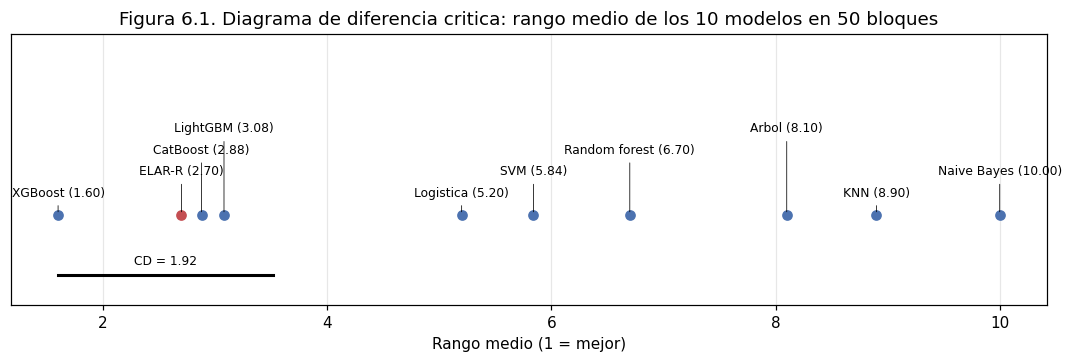

,KNN,Naive Bayes,Arbol,Random forest,SVM,Logistica,XGBoost,LightGBM,CatBoost
p Nemenyi frente a ELAR-R,0.0,0.0,1.110223e-16,1.777975e-09,0.00001,0.001501,0.724846,0.999805,1.0


In [6]:
f = pe["friedman"]
r = pd.Series(dict(zip(pe["modelos"], f["rangos_medios"]))).sort_values()
k, N = f["k"], f["N"]
CD = studentized_range.ppf(0.95, k, np.inf) / np.sqrt(2) * np.sqrt(k * (k + 1) / (6 * N))
print(f"Friedman: chi2 = {f['chi2']:.1f} (gl = {f['gl']}), p = {f['p']:.1e}; Iman-Davenport F = {f['F_iman_davenport']:.1f}, p = {f['p_F']:.1e}")
print(f"Diferencia critica de Nemenyi (k = {k}, N = {N}): {CD:.2f}")
fig, ax = plt.subplots(figsize=(10, 3.4))
for i, (mod, v) in enumerate(r.items()):
    ax.plot(v, 0, "o", color="#C44E52" if mod == "elar" else "#4C72B0")
    ax.annotate(f"{NOMBRE[mod]} ({v:.2f})", (v, 0), xytext=(0, 12 + 14 * (i % 4)), textcoords="offset points",
                ha="center", fontsize=8, arrowprops={"arrowstyle": "-", "lw": 0.5})
ax.plot([r.iloc[0], r.iloc[0] + CD], [-0.4, -0.4], "k-", lw=2)
ax.text(r.iloc[0] + CD / 2, -0.33, f"CD = {CD:.2f}", ha="center", fontsize=8)
ax.set(title="Figura 6.1. Diagrama de diferencia critica: rango medio de los 10 modelos en 50 bloques",
       xlabel="Rango medio (1 = mejor)", ylim=(-0.6, 1.2), yticks=[])
plt.tight_layout(); plt.show()
nem = pd.DataFrame(pe["nemenyi_p"]).loc[["elar"]].T.rename(index=NOMBRE).rename(columns={"elar": "p Nemenyi frente a ELAR-R"})
nem.drop(index="ELAR-R").sort_values("p Nemenyi frente a ELAR-R").T

**Lectura de la figura 6.1.** Friedman rechaza con fuerza que los 10 modelos sean equivalentes. Con la corrección de Nemenyi, que es
conservadora porque controla las 45 comparaciones por pares a la vez, ELAR-R no se distingue de los otros tres modelos de boosting (sus
rangos medios caen dentro de una CD) y sí de los seis restantes. Por eso Nemenyi no detecta la ventaja de XGBoost que las pruebas
pareadas de la sección 6.4 sí encuentran: tiene menos potencia, no contradice esas pruebas.

## 6.6 Decisiones con el umbral de coste: McNemar

Con el umbral que minimiza el coste esperado (un falso negativo cuesta 10 falsos positivos), elegido en las predicciones fuera de muestra
de cada modelo, se comparan las decisiones de ELAR-R y de cada benchmark sobre la prueba.

In [7]:
mc = pd.read_csv(RAIZ / "resultados_e4" / "f7_estadistica" / "mcnemar_home_credit.csv")
mc["benchmark"] = mc["benchmark"].map(NOMBRE)
mc = mc.rename(columns={"a_acierta_b_falla": "ELAR-R acierta, benchmark falla", "b_acierta_a_falla": "benchmark acierta, ELAR-R falla"})
mc = mc.astype({"ELAR-R acierta, benchmark falla": int, "benchmark acierta, ELAR-R falla": int})
mc["p"] = mc["p"].map(lambda v: f"{v:.2g}"); mc["p_holm"] = mc["p_holm"].map(lambda v: f"{v:.2g}")
mc.set_index("benchmark")

,"ELAR-R acierta, benchmark falla","benchmark acierta, ELAR-R falla",p,p_holm
benchmark,,,,
Arbol,5966,4089,1.5e-78,1.1e-77
CatBoost,2002,1753,5.2e-05,5.2e-05
KNN,7553,5548,6.8e-69,3.4e-68
LightGBM,1685,2453,5.9e-33,1.8e-32
Logistica,2908,1586,1.1e-87,8.5e-87
Naive Bayes,10346,5979,5e-259,4.5e-258
Random forest,3491,2157,4.9e-71,2.9e-70
SVM,2545,2129,1.2e-09,2.5e-09
XGBoost,2413,1556,2.3e-42,9.2e-42


**Lectura de la tabla 6.5.** Todas las diferencias en las decisiones son significativas, porque con 61,503 filas hasta un desacuerdo
pequeño es detectable. ELAR-R acierta en más casos discordantes que 8 de los 9 benchmarks, XGBoost incluido, y en menos que LightGBM.
Esto no contradice la sección 6.4: McNemar compara aciertos con umbrales distintos para cada modelo, no la capacidad de ordenar (AUC).
Sirve para el dashboard, porque son las decisiones que vería un analista, pero no entra en el veredicto R3.

## 6.7 Veredicto sobre R3

La regla del protocolo (sec. 5) exige, a la vez, que ELAR-R tenga el mayor AUC externo medio, que al menos 3 pruebas rechacen frente al
**mejor** benchmark en la dirección favorable, que $|\delta| \ge 0.147$ y que se cumpla la hipótesis complementaria.

In [8]:
mejor = max((m for m in pe["modelos"] if m != "elar"), key=lambda m: pe["auc_oof"][m])
c = pe["comparaciones_elar_vs"][mejor]
favorables = sum(p < 0.05 for p in c["p_holm"].values()) if c["dif_oof"] > 0 else 0
criterios = pd.DataFrame([
    ("1. Mayor AUC externo medio", f"ELAR-R {pe['auc_oof']['elar']:.4f} vs {NOMBRE[mejor]} {pe['auc_oof'][mejor]:.4f}", pe["auc_oof"]["elar"] > pe["auc_oof"][mejor]),
    ("2. >= 3 pruebas favorables frente al mejor", f"{favorables} favorables; {c['significativas_holm']} significativas en contra", favorables >= 3),
    ("3. |delta de Cliff| >= 0.147 a favor", f"delta = {c['cliff_pareado'][0]:+.2f}", c["cliff_pareado"][0] >= 0.147),
    ("4. Consistencia en los 3 conjuntos adicionales (H3 original = H2 de la sec. 8)", "ver cap. 7: ELAR-R significativamente peor que CatBoost en Bank marketing", False),
], columns=["criterio", "resultado", "cumple"]).set_index("criterio")
print("R3:", "CUMPLE" if criterios["cumple"].all() else "NO SE CUMPLE")
criterios

R3: NO SE CUMPLE


,resultado,cumple
criterio,,
1. Mayor AUC externo medio,ELAR-R 0.7838 vs XGBoost 0.7877,False
2. >= 3 pruebas favorables frente al mejor,0 favorables; 4 significativas en contra,False
3. |delta de Cliff| >= 0.147 a favor,delta = -0.60,False
4. Consistencia en los 3 conjuntos adicionales (H3 original = H2 de la sec. 8),ver cap. 7: ELAR-R significativamente peor que...,False


**Conclusión.** En igualdad de condiciones, **ELAR-R no cumple R3**: el mejor benchmark (XGBoost) es significativamente mejor, por lo que
tampoco se cumple la superioridad frente a cada familia (le falla XGBoost), y en los conjuntos adicionales no se cumple el criterio de
consistencia de la guía (capítulo 7). El resultado se reporta tal cual, como pide el protocolo.
ELAR-R sí es competitivo con los métodos recientes del estado del arte (empate con LightGBM y CatBoost), supera con claridad a los otros
seis ganadores de familia y, como muestra el capítulo 7, es el más estable de los modelos de cabeza. La ventaja de 0.0146 de AUC frente
al XGBoost del E3 (enmienda E1) se debe a la ingeniería de variables y no al algoritmo.